# Predicția pierderii clienților – V1

Antrenăm și optimizăm separat **Regresie Logistică, Decision Tree și KNN**. Păstrăm **60% antrenare / 20% validare / 20% test**, fără să folosim testul în V1.

Evaluăm prin **Accuracy, Precision pentru clienții care pleacă (`Churn = Yes`), raportul de clasificare și matricea de confuzie**. Optimizarea hiperparametrilor rămâne cu `GridSearchCV` și criteriul F1.

### 1. Importăm bibliotecile și încărcăm datele
Importăm bibliotecile necesare pentru prelucrarea datelor, antrenarea celor trei algoritmi, optimizarea hiperparametrilor și evaluarea predicțiilor. Apoi încărcăm datasetul Telco Customer Churn și verificăm numărul de clienți, caracteristicile și distribuția variabilei Churn.

In [ ]:
# Biblioteci pentru date și grafice
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Biblioteci pentru împărțirea datelor și căutarea hiperparametrilor
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# Cei 3 algoritmi de clasificare
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Metrici pentru verificarea predicțiilor
from sklearn.metrics import (accuracy_score, precision_score,
                             confusion_matrix, classification_report)
import joblib

RANDOM_STATE = 42  # Ne asigurăm că obținem aceeași împărțire la fiecare rulare
sns.set_theme(style="whitegrid")

# Citim datasetul public Telco Customer Churn
url = "https://raw.githubusercontent.com/rstudio/keras-customer-churn/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("Dimensiunea datasetului:", df.shape)
display(df.head(3))
print("Distribuția Churn:")
print(df["Churn"].value_counts())

Dimensiunea datasetului: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


Distribuția Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 2. Pregătim datele și le împărțim
Transformăm coloana TotalCharges în valori numerice, separăm cele 19 caracteristici de variabila țintă Churn și împărțim datele în 60% antrenare, 20% validare și 20% test. Păstrăm proporțiile claselor și rezervăm setul de test pentru evaluarea finală.

In [ ]:
# Transformăm TotalCharges în numere; spațiile goale devin valori lipsă (NaN)
model_df = df.copy()
model_df["TotalCharges"] = pd.to_numeric(model_df["TotalCharges"], errors="coerce")

# X = informațiile despre clienți; y = răspunsul pe care vrem să îl prezicem
X = model_df.drop(columns=["customerID", "Churn"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})
assert y.notna().all(), "Există valori Churn necunoscute."
print("Caracteristici de intrare:", X.shape[1])
print("Valori lipsă în TotalCharges:", X["TotalCharges"].isna().sum())

# Mai întâi păstrăm 20% numai pentru testul final
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
# Din restul de 80%, luăm un sfert pentru validare = 20% din tot datasetul
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
)
print("Train:", len(X_train), "| Validare:", len(X_val), "| Test:", len(X_test))

# Salvăm ce clienți intră în fiecare set, ca să putem reproduce împărțirea la V2
partitii = pd.DataFrame({"customerID": df["customerID"], "set": "test"})
partitii.loc[X_train.index, "set"] = "train"
partitii.loc[X_val.index, "set"] = "validation"
partitii.to_csv("partitii_clienti_V1.csv", index=False)

# Niciun client nu trebuie să apară în două seturi
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print("Împărțire verificată. Testul rămâne nefolosit la V1.")

Caracteristici de intrare: 19
Valori lipsă în TotalCharges: 11
Train: 4225 | Validare: 1409 | Test: 1409
Împărțire verificată. Testul rămâne nefolosit la V1.


### 3. Pregătim preprocesarea și evaluarea
Pregătim datele completând valorile lipsă, standardizând caracteristicile numerice și transformând categoriile text în numere. Folosim Pipeline și ColumnTransformer pentru preprocesare, validarea încrucișată cu 3 folduri pentru optimizarea hiperparametrilor și o funcție pentru evaluarea modelelor prin Accuracy și Precisione.

In [ ]:
# Identificăm automat coloanele numerice și cele categorice
coloane_numerice = X_train.select_dtypes(include=np.number).columns.tolist()
coloane_categorice = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Pentru numere: completăm lipsurile cu mediana și standardizăm valorile
preprocesare_numerica = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
# Pentru text: completăm lipsurile cu valoarea cea mai frecventă și codificăm categoriile
preprocesare_categorica = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocesor = ColumnTransformer([
    ("num", preprocesare_numerica, coloane_numerice),
    ("cat", preprocesare_categorica, coloane_categorice)
])

# Folosim 3 părți (folduri) numai din train pentru alegerea hiperparametrilor
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Pentru fiecare model evaluăm Accuracy și Precision pentru clasa 1 (pleacă)
def evalueaza(nume, model, etapa):
    predictii = model.predict(X_val)  # 0 = rămâne, 1 = pleacă
    return {
        "Algoritm": nume,
        "Etapa": etapa,
        "Accuracy": accuracy_score(y_val, predictii),
        "Precision": precision_score(y_val, predictii, zero_division=0)
    }

modele_initiale = {}
modele_optimizate = {}
rezultate_cv = []
print("Preprocesarea și evaluarea sunt pregătite.")

Preprocesarea și evaluarea sunt pregătite.


### 4. Regresie Logistică – antrenare
Regresia Logistică învață din clienții pentru care știm deja dacă au plecat sau nu. În timpul antrenării, își ajustează coeficienții pentru a face estimări cât mai bune. Apoi, pentru un client nou, folosește caracteristicile și coeficienții învățați ca să calculeze probabilitatea de abandon și să prezică Yes sau No.

In [ ]:
# Varianta inițială
model_lr = Pipeline([
    ("preprocesare", clone(preprocesor)),
    ("clasificator", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model_lr.fit(X_train, y_train)
modele_initiale["Regresie Logistică"] = model_lr
print("Antrenare finalizată: Regresie Logistică")

Antrenare finalizată: Regresie Logistică


### 5. Regresie Logistică – optimizarea hiperparametrilor

Optimizăm modelul folosind `GridSearchCV`, care testează diferite valori pentru `C` (regularizarea) și `class_weight` (ponderile claselor). Comparăm combinațiile prin validare încrucișată cu 3 folduri, folosind F1-score, și selectăm setările care oferă cele mai bune rezultate.

In [ ]:
# Hiperparametri testați: C controlează regularizarea; balanced echilibrează clasele
parametri_lr = {
    "clasificator__C": [0.1, 1.0, 10.0],
    "clasificator__class_weight": [None, "balanced"]
}
cautare_lr = GridSearchCV(model_lr, parametri_lr, scoring="f1", cv=cv, n_jobs=2)
cautare_lr.fit(X_train, y_train)
modele_optimizate["Regresie Logistică"] = cautare_lr.best_estimator_
rezultate_cv.append({"Algoritm": "Regresie Logistică", "F1_CV": cautare_lr.best_score_,
                    "Hiperparametri": str(cautare_lr.best_params_)})
print("Regresie Logistică - setări alese:", cautare_lr.best_params_)

Regresie Logistică - setări alese: {'clasificator__C': 0.1, 'clasificator__class_weight': 'balanced'}


### 6. Decision Tree – antrenare
Antrenăm algoritmul Decision Tree pe setul de antrenare. Acesta construiește un arbore de decizie, împărțind clienții în grupuri pe baza caracteristicilor lor, pentru a învăța reguli care prezic dacă un client va pleca sau va rămâne.

In [ ]:
# Varianta inițială
model_tree = Pipeline([
    ("preprocesare", clone(preprocesor)),
    ("clasificator", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
model_tree.fit(X_train, y_train)
modele_initiale["Decision Tree"] = model_tree
print("Antrenare finalizată: Decision Tree")

Antrenare finalizată: Decision Tree


### 7. Decision Tree – optimizarea hiperparametrilor
Folosim GridSearchCV pentru a testa diferite valori ale adâncimii arborelui (max_depth), numărului minim de exemple dintr-o frunză (min_samples_leaf) și ponderilor claselor (class_weight). Comparăm combinațiile prin validare încrucișată cu 3 folduri, folosind F1-score, și alegem setările care oferă cele mai bune rezultate.

In [ ]:
# Hiperparametri: adâncimea arborelui, mărimea frunzelor și ponderile claselor
parametri_tree = {
    "clasificator__max_depth": [3, 5, 8],
    "clasificator__min_samples_leaf": [5, 15],
    "clasificator__class_weight": [None, "balanced"]
}
cautare_tree = GridSearchCV(model_tree, parametri_tree, scoring="f1", cv=cv, n_jobs=2)
cautare_tree.fit(X_train, y_train)
modele_optimizate["Decision Tree"] = cautare_tree.best_estimator_
rezultate_cv.append({"Algoritm": "Decision Tree", "F1_CV": cautare_tree.best_score_,
                    "Hiperparametri": str(cautare_tree.best_params_)})
print("Decision Tree - setări alese:", cautare_tree.best_params_)

Decision Tree - setări alese: {'clasificator__class_weight': 'balanced', 'clasificator__max_depth': 3, 'clasificator__min_samples_leaf': 5}


### 8. KNN – antrenare
Antrenăm algoritmul KNN folosind inițial 5 vecini. Acesta compară fiecare client cu cei mai apropiați clienți din setul de antrenare și prezice dacă va pleca sau va rămâne pe baza votului majoritar.

In [ ]:
# Varianta inițială: 5 vecini
model_knn = Pipeline([
    ("preprocesare", clone(preprocesor)),
    ("clasificator", KNeighborsClassifier(n_neighbors=5))
])
model_knn.fit(X_train, y_train)
modele_initiale["KNN"] = model_knn
print("Antrenare finalizată: KNN")

Antrenare finalizată: KNN


### 9. KNN – optimizarea hiperparametrilor
Am optimizat KNN folosind GridSearchCV. Am testat 5, 11 și 21 de vecini și două metode de votare: uniform, în care toți vecinii au aceeași importanță, și distance, în care vecinii mai apropiați au o influență mai mare. Cele mai bune setări au fost 21 de vecini și votare uniformă.

In [ ]:
# Hiperparametri: câți vecini consultăm și dacă vecinii apropiați cântăresc mai mult
parametri_knn = {
    "clasificator__n_neighbors": [5, 11, 21],
    "clasificator__weights": ["uniform", "distance"]
}
cautare_knn = GridSearchCV(model_knn, parametri_knn, scoring="f1", cv=cv, n_jobs=2)
cautare_knn.fit(X_train, y_train)
modele_optimizate["KNN"] = cautare_knn.best_estimator_
rezultate_cv.append({"Algoritm": "KNN", "F1_CV": cautare_knn.best_score_,
                    "Hiperparametri": str(cautare_knn.best_params_)})
print("KNN - setări alese:", cautare_knn.best_params_)

KNN - setări alese: {'clasificator__n_neighbors': 21, 'clasificator__weights': 'uniform'}


### 10. Comparăm Accuracy, Precision și rapoartele de clasificare
Evaluăm cei trei algoritmi pe setul de validare, comparând Accuracy și Precision înainte și după optimizarea hiperparametrilor. Afișăm și hiperparametrii selectați prin GridSearchCV, iar pentru modelele optimizate generăm rapoarte de clasificare care includ Precision, Recall și F1-score.

In [ ]:
# Comparăm cele trei modele inițiale cu cele trei modele optimizate
lista_algoritmi = ["Regresie Logistică", "Decision Tree", "KNN"]
rezultate = []
for nume in lista_algoritmi:
    rezultate.append(evalueaza(nume, modele_initiale[nume], "Inițial"))
    rezultate.append(evalueaza(nume, modele_optimizate[nume], "Optimizat"))

# Accuracy = proporția totală a predicțiilor corecte
# Precision = dintre cei preziși că pleacă, câți au plecat în realitate?
comparatie = pd.DataFrame(rezultate)
display(comparatie.round(3))

# Hiperparametrii sunt cei aleși de GridSearchCV pe train
print("Hiperparametrii aleși prin GridSearchCV:")
display(pd.DataFrame(rezultate_cv).round(3))

# Raportul complet afișează automat și Recall, F1 și support pentru fiecare clasă
for nume in lista_algoritmi:
    predictii = modele_optimizate[nume].predict(X_val)
    print("\nRaport de clasificare –", nume, "(optimizat):")
    print(classification_report(
        y_val, predictii,
        labels=[0, 1], target_names=["No (rămâne)", "Yes (pleacă)"],
        digits=3, zero_division=0
    ))
print("Evaluarea este făcută doar pe validare; testul rămâne rezervat.")

,Algoritm,Etapa,Accuracy,Precision
0,Regresie Logistică,Inițial,0.803,0.660
1,Regresie Logistică,Optimizat,0.748,0.517
2,Decision Tree,Inițial,0.737,0.505
3,Decision Tree,Optimizat,0.735,0.500
4,KNN,Inițial,0.760,0.551
5,KNN,Optimizat,0.786,0.611


Hiperparametrii aleși prin GridSearchCV:


,Algoritm,F1_CV,Hiperparametri
0,Regresie Logistică,0.631,"{'clasificator__C': 0.1, 'clasificator__class_..."
1,Decision Tree,0.626,"{'clasificator__class_weight': 'balanced', 'cl..."
2,KNN,0.592,"{'clasificator__n_neighbors': 21, 'clasificato..."



Raport de clasificare – Regresie Logistică (optimizat):
              precision    recall  f1-score   support

 No (rămâne)      0.907     0.732     0.810      1035
Yes (pleacă)      0.517     0.791     0.625       374

    accuracy                          0.748      1409
   macro avg      0.712     0.762     0.718      1409
weighted avg      0.803     0.748     0.761      1409


Raport de clasificare – Decision Tree (optimizat):
              precision    recall  f1-score   support

 No (rămâne)      0.899     0.720     0.799      1035
Yes (pleacă)      0.500     0.775     0.608       374

    accuracy                          0.735      1409
   macro avg      0.699     0.748     0.704      1409
weighted avg      0.793     0.735     0.749      1409


Raport de clasificare – KNN (optimizat):
              precision    recall  f1-score   support

 No (rămâne)      0.840     0.876     0.858      1035
Yes (pleacă)      0.611     0.537     0.572       374

    accuracy                   

### 11. Grafice: Accuracy și Precision
Fiecare algoritm are un grafic simplu cu două metrici: Accuracy și Precision, înainte și după optimizare.

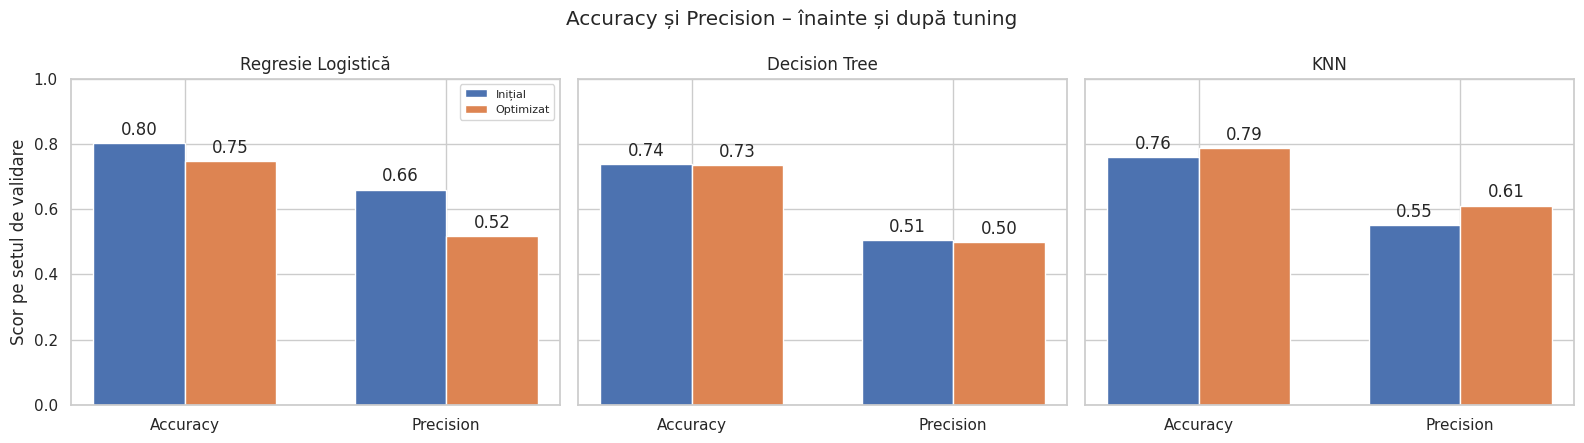

In [ ]:
# Trei grafice alăturate: câte unul pentru fiecare algoritm
fig, axe = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
metrici = ["Accuracy", "Precision"]

for ax, nume in zip(axe, lista_algoritmi):
    r = comparatie[comparatie["Algoritm"] == nume].set_index("Etapa")
    x = np.arange(2)
    latime = 0.35
    initial = [r.loc["Inițial", m] for m in metrici]
    optimizat = [r.loc["Optimizat", m] for m in metrici]

    bare1 = ax.bar(x - latime / 2, initial, latime, label="Inițial")
    bare2 = ax.bar(x + latime / 2, optimizat, latime, label="Optimizat")
    ax.bar_label(bare1, fmt="%.2f", padding=3)
    ax.bar_label(bare2, fmt="%.2f", padding=3)
    ax.set_xticks(x, metrici)
    ax.set_ylim(0, 1)
    ax.set_title(nume)

axe[0].set_ylabel("Scor pe setul de validare")
axe[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Accuracy și Precision – înainte și după tuning")
plt.tight_layout()
plt.show()

### 12. Graficul raportului de clasificare – cele trei modele
Reprezentăm grafic Precision, Recall și F1-score pentru clienții care pleacă , comparând fiecare algoritm înainte și după optimizare.

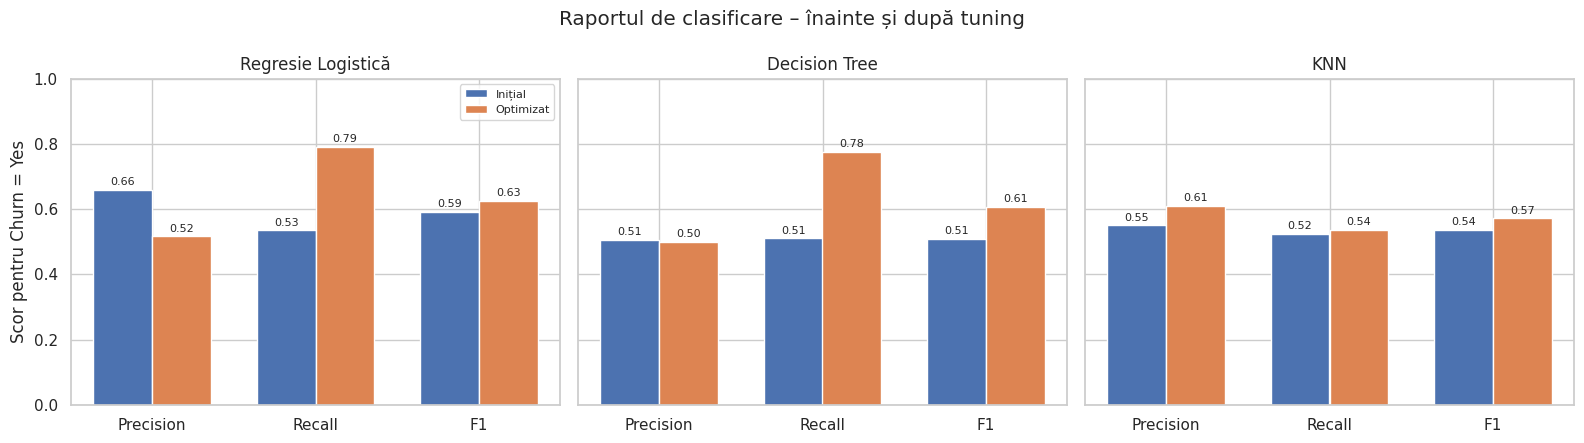

In [ ]:
# Facem câte un grafic pentru fiecare dintre cei 3 algoritmi.
fig, axe = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
metrici = ["precision", "recall", "f1-score"]

for ax, nume in zip(axe, lista_algoritmi):
    # Extragem valorile clasei Yes (clientul pleacă) din rapoartele de clasificare.
    valori = []
    for model in [modele_initiale[nume], modele_optimizate[nume]]:
        predictii = model.predict(X_val)
        raport = classification_report(y_val, predictii, labels=[0, 1],
                                       target_names=["No", "Yes"],
                                       output_dict=True, zero_division=0)
        valori.append([raport["Yes"][metrica] for metrica in metrici])

    # Cele două serii de bare: înainte și după optimizare.
    x = np.arange(len(metrici))
    bare1 = ax.bar(x - 0.18, valori[0], 0.36, label="Inițial")
    bare2 = ax.bar(x + 0.18, valori[1], 0.36, label="Optimizat")
    ax.set_xticks(x, ["Precision", "Recall", "F1"])
    ax.set_ylim(0, 1)
    ax.set_title(nume)
    ax.bar_label(bare1, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(bare2, fmt="%.2f", padding=2, fontsize=8)

axe[0].set_ylabel("Scor pentru Churn = Yes")
axe[0].legend(fontsize=8)
fig.suptitle("Raportul de clasificare – înainte și după tuning")
plt.tight_layout()
plt.show()


### 13. Afișăm predicții pentru 10 clienți
Folosim cele trei modele optimizate pentru a prezice dacă fiecare client din setul de validare va pleca sau va rămâne. Afișăm primele 10 exemple, comparând predicțiile fiecărui algoritm cu răspunsurile reale, pentru a observa care predicții sunt corecte și care sunt greșite.

In [ ]:
# 0 înseamnă că rămâne; 1 înseamnă că pleacă
# Afișăm atât realitatea, cât și predicțiile modelelor
predictii_clienti = pd.DataFrame({
    "Client": df.loc[X_val.index, "customerID"].to_numpy(),
    "Churn real": np.where(y_val.to_numpy() == 1, "Yes", "No")
})
for nume in lista_algoritmi:
    predictii = modele_optimizate[nume].predict(X_val)
    predictii_clienti[nume] = np.where(predictii == 1, "Yes", "No")

display(predictii_clienti.head(10))

,Client,Churn real,Regresie Logistică,Decision Tree,KNN
0,7206-PQBBZ,No,Yes,Yes,Yes
1,9605-WGJVW,No,Yes,Yes,Yes
2,4123-DVHPH,No,Yes,Yes,Yes
3,3196-NVXLZ,No,Yes,Yes,Yes
4,2192-OZITF,No,No,No,No
5,4939-KYYPY,No,No,No,No
6,4718-WXBGI,No,No,No,No
7,3230-IUALN,No,No,No,No
8,1450-GALXR,Yes,Yes,Yes,Yes
9,0613-WUXUM,No,No,No,No


### 14. Matricele de confuzie – predicții corecte și greșite
Pentru fiecare algoritm afișăm matricea inițială și pe cea optimizată. Numerele arată cine a fost clasificat corect sau greșit.

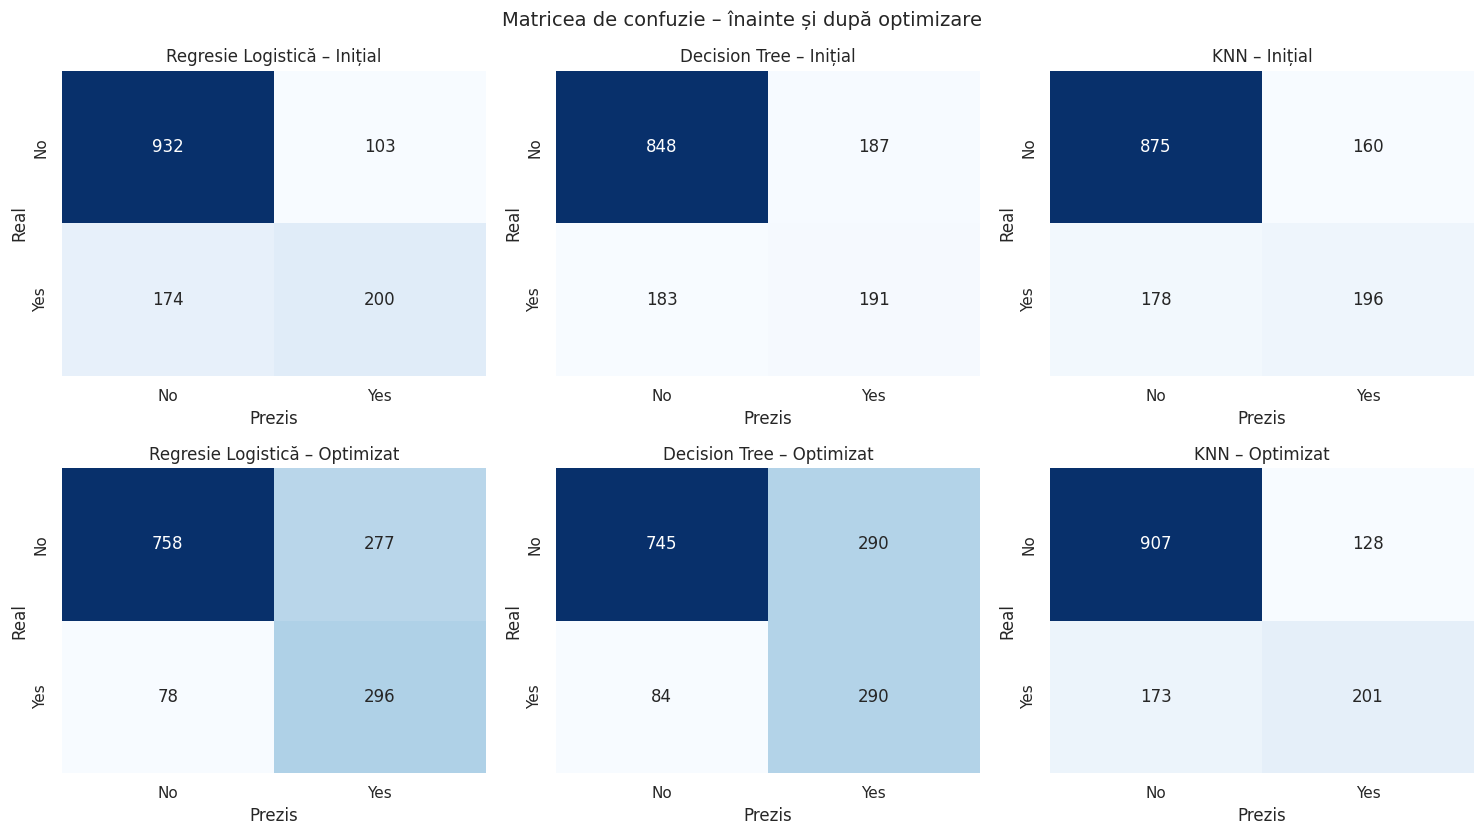

In [ ]:
# Două rânduri: inițial și optimizat; trei coloane: algoritmii
fig, axe = plt.subplots(2, 3, figsize=(15, 8.5))

for rand, (etapa, modele) in enumerate([
    ("Inițial", modele_initiale),
    ("Optimizat", modele_optimizate)
]):
    for coloana, nume in enumerate(lista_algoritmi):
        predictii = modele[nume].predict(X_val)
        matrice = confusion_matrix(y_val, predictii, labels=[0, 1])
        ax = axe[rand, coloana]

        sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax)
        ax.set_title(f"{nume} – {etapa}")
        ax.set_xlabel("Prezis")
        ax.set_ylabel("Real")

fig.suptitle("Matricea de confuzie – înainte și după optimizare", fontsize=14)
plt.tight_layout()
plt.show()

# În matrice: sus-stânga și jos-dreapta = predicții corecte
# Jos-stânga = clienți care au plecat, dar modelul a prezis că rămân

### 15. Salvăm rezultatele și modelele pentru V2
Păstrăm rezultatele, hiperparametrii și modelele optimizate pentru a le putea folosi în etapele următoare.

In [ ]:
# Salvăm comparația Accuracy/Precision și hiperparametrii găsiți
comparatie.to_csv("rezultate_V1.csv", index=False)
pd.DataFrame(rezultate_cv).to_csv("hiperparametri_V1.csv", index=False)

# Salvăm fiecare model optimizat împreună cu preprocesarea sa
joblib.dump(modele_optimizate["Regresie Logistică"], "model_V1_regresie_logistica.joblib")
joblib.dump(modele_optimizate["Decision Tree"], "model_V1_decision_tree.joblib")
joblib.dump(modele_optimizate["KNN"], "model_V1_knn.joblib")

print("Modelele și rezultatele V1 au fost salvate în sesiunea Colab.")
print("Pentru V2 păstrează și partitii_clienti_V1.csv, creat la celula 2.")
print("Setul de test nu a fost folosit; îl păstrăm pentru evaluarea finală.")

Modelele și rezultatele V1 au fost salvate în sesiunea Colab.
Pentru V2 păstrează și partitii_clienti_V1.csv, creat la celula 2.
Setul de test nu a fost folosit; îl păstrăm pentru evaluarea finală.
